# Task 4 — Random Forests & Ensembles
 

In [1]:
import sys
import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)

3.13.9 2.3.4 2.3.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 3246
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


SEED = 3246

In [3]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

In [4]:
import math

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, cross_validate


def paired_diff(a, b):
    """Paired difference a - b: (diffs, mean, std, inside_spread)."""
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    return d, d.mean(), d.std(), abs(d.mean()) <= d.std()


def show_paired(name_a, name_b, a, b):
    """Print the five paired differences, their mean/std and the verdict."""
    d, m, s, inside = paired_diff(a, b)
    if inside:
        verdict = "INSIDE the fold spread -> no winner, the data cannot separate them"
    else:
        verdict = f"outside the spread -> {name_a if m > 0 else name_b} is better"
    print(f"{name_a} - {name_b}: diffs={np.round(d, 4)}  mean={m:+.4f}  std={s:.4f}  => {verdict}")
    return d, m, s, inside


def cv_table(scores):
    """DataFrame: five fold scores + mean + std (np.std, ddof=0) for each model."""
    rows = {k: list(v) + [np.mean(v), np.std(v)] for k, v in scores.items()}
    return pd.DataFrame(rows, index=[f"fold{i+1}" for i in range(5)] + ["mean", "std"]).T.round(4)

## Part 1 — Bagging and out-of-bag estimates

In [5]:
def oob_mask(sample_indices, n_samples):
    """Boolean mask of the rows that do NOT occur in sample_indices."""
    mask = np.ones(n_samples, dtype=bool)
    idx = np.asarray(sample_indices, dtype=int)   # works for lists, arrays and the empty list
    mask[idx] = False
    return mask


# examples from the task
assert oob_mask([0, 2, 2], 5).tolist() == [False, True, False, True, True]
assert oob_mask([], 3).tolist() == [True, True, True]
assert oob_mask(np.array([3, 0]), 4).tolist() == [False, True, True, False]
print("oob_mask: all examples OK")

oob_mask: all examples OK


In [6]:
bag.fit(X_train, y_train)
n = len(X_train)
shares = [oob_mask(s, n).mean() for s in bag.estimators_samples_]
mean_oob_share = float(np.mean(shares))
print("n (training rows)               :", n)
print("my mean out-of-bag share        :", round(mean_oob_share, 4))
print("my mean in-bag share            :", round(1 - mean_oob_share, 4))
print("formula (1 - 1/n)^n             :", round((1 - 1 / n) ** n, 4))
print("formula 1 - (1 - 1/n)^n         :", round(1 - (1 - 1 / n) ** n, 4))

n (training rows)               : 3153
my mean out-of-bag share        : 0.3667
my mean in-bag share            : 0.6333
formula (1 - 1/n)^n             : 0.3678
formula 1 - (1 - 1/n)^n         : 0.6322


In [7]:
votes = np.zeros((n, 2), dtype=int)
for est, samples in zip(bag.estimators_, bag.estimators_samples_):
    m = oob_mask(samples, n)                       # rows this tree never saw
    pred = est.predict(X_train[m])                 # its votes on those rows
    votes[np.where(m)[0], pred] += 1
oob_pred = votes.argmax(axis=1)                    # tie -> class 0
my_oob_acc = float((oob_pred == y_train).mean())
print("my out-of-bag accuracy           :", round(my_oob_acc, 4))
print("bag.oob_score_ (scikit-learn)    :", round(bag.oob_score_, 4))

my out-of-bag accuracy           : 0.9432
bag.oob_score_ (scikit-learn)    : 0.9432


In [8]:
models5 = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
cv5 = {name: cross_validate(m, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
       for name, m in models5.items()}
display(cv_table(cv5))
d_bag_tree = show_paired("bag", "tree", cv5["bag"], cv5["tree"])
d_rf_tree = show_paired("rf", "tree", cv5["rf"], cv5["tree"])
d_baglr_lr = show_paired("bag_lr", "lr", cv5["bag_lr"], cv5["lr"])

,fold1,fold2,fold3,fold4,fold5,mean,std
tree,0.9049,0.9033,0.9065,0.9063,0.8968,0.9036,0.0036
bag,0.9239,0.9334,0.9366,0.9317,0.9365,0.9324,0.0046
rf,0.9398,0.9477,0.9493,0.9508,0.9476,0.9470,0.0038
lr,0.9223,0.9334,0.9303,0.9429,0.9365,0.9331,0.0068
bag_lr,0.9271,0.9319,0.9334,0.9429,0.9381,0.9347,0.0054


bag - tree: diffs=[0.019  0.0301 0.0301 0.0254 0.0397]  mean=+0.0289  std=0.0068  => outside the spread -> bag is better
rf - tree: diffs=[0.0349 0.0444 0.0428 0.0444 0.0508]  mean=+0.0435  std=0.0051  => outside the spread -> rf is better
bag_lr - lr: diffs=[ 0.0048 -0.0016  0.0032  0.      0.0016]  mean=+0.0016  std=0.0022  => INSIDE the fold spread -> no winner, the data cannot separate them


In [9]:
rf.fit(X_train, y_train)
p_rf = rf.score(X_test, y_test)
se_rf = math.sqrt(p_rf * (1 - p_rf) / len(X_test))
cv_rf_mean, cv_rf_std = np.mean(cv5["rf"]), np.std(cv5["rf"])
print(f"rf.oob_score_            : {rf.oob_score_:.4f}")
print(f"rf cross-validation mean : {cv_rf_mean:.4f}  (std of folds {cv_rf_std:.4f})")
print(f"rf test accuracy p       : {p_rf:.4f}  standard error {se_rf:.4f}")
gap = abs(rf.oob_score_ - cv_rf_mean)
print(f"|oob - cv mean| = {gap:.4f}  vs  std of folds {cv_rf_std:.4f}  ->",
      "IN agreement" if gap <= cv_rf_std else "NOT in agreement")
print(f"|test - oob| = {abs(p_rf - rf.oob_score_):.4f},  |test - cv mean| = {abs(p_rf - cv_rf_mean):.4f},  1 SE = {se_rf:.4f}")

rf.oob_score_            : 0.9512
rf cross-validation mean : 0.9470  (std of folds 0.0038)
rf test accuracy p       : 0.9467  standard error 0.0069
|oob - cv mean| = 0.0041  vs  std of folds 0.0038  -> NOT in agreement
|test - oob| = 0.0044,  |test - cv mean| = 0.0003,  1 SE = 0.0069


**Part 1 — my answers**

**Out-of-bag share and accuracy.** On average a tree leaves 36.67 % of the training rows out of bag (in-bag 63.33 %). The formulas give 36.78 % and 63.22 %, so the simulation matches the theory: with n = 3153 the chance that a row is never drawn is (1 − 1/n)^n ≈ 1/e ≈ 0.37. My hand-made out-of-bag accuracy (0.9432) is exactly equal to bag.oob_score_ (0.9432).

**(a) Did bagging help?**

For the single decision tree, yes. Bagging raised the CV accuracy from 0.9036 to 0.9324, which is +0.0289 on average. The gain shows up on all five folds (differences: 0.0190, 0.0301, 0.0301, 0.0254, 0.0397). The mean difference is clearly larger than the std of the differences (0.0068), so it is outside the fold spread and not just noise. The random forest goes even further (+0.0435 over the tree, std 0.0051).

For logistic regression, no clear change. bag_lr − lr is only +0.0016 on average, with a std of 0.0022, and the differences even change sign (+0.0048, −0.0016, +0.0032, 0.0000, +0.0016). This is inside the fold spread, so my data cannot tell the two models apart.

Why the two cases differ: a fully grown tree is very unstable. If I change a few training emails, I get quite a different tree, so its mistakes are partly random. When I average 100 trees trained on different bootstrap samples, these random mistakes cancel out, and the vote is more accurate than any single tree. Logistic regression is already stable: a bootstrap sample gives almost the same model as the original data. The 50 bagged copies are nearly identical, so averaging them has almost nothing to cancel.

**(b) Is the out-of-bag score a fair stand-in for cross-validation?**

The forest's oob_score_ is 0.9512 and its CV mean is 0.9470. The gap is 0.0041, while the std of the forest's five fold scores is 0.0038. By the rule of this task the two numbers are therefore not in agreement, but only just: the gap is a little larger than the std, and it is less than half a percentage point. A possible reason is that each CV forest is trained on only 80 % of the training split, while the out-of-bag estimate comes from forests that saw all of it, so the OOB score comes out slightly higher.

On the test split the forest scored 0.9467 with a standard error of 0.0069. The CV mean is almost equal to it (difference 0.0003), and the OOB score is also well within one standard error (difference 0.0044). So all three numbers tell the same story: the forest is right on about 95 % of the emails, and for practical purposes the out-of-bag score is a good stand-in for cross-validation.

## Part 2 — Evaluating the filter: curves, a threshold, importances

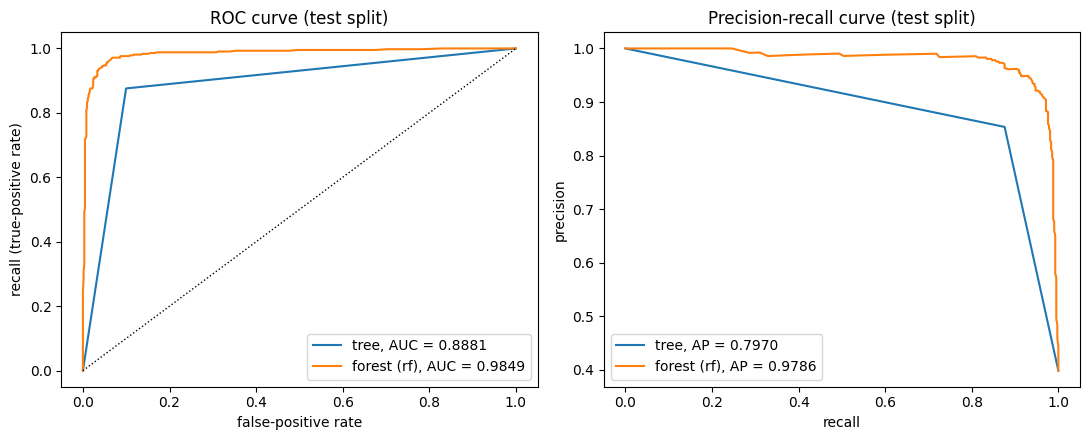

In [10]:
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)
scores_test = {"tree": tree.predict_proba(X_test)[:, 1], "forest (rf)": rf.predict_proba(X_test)[:, 1]}

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, s in scores_test.items():
    f, t_, _ = roc_curve(y_test, s)
    ax[0].plot(f, t_, label=f"{name}, AUC = {roc_auc_score(y_test, s):.4f}")
    pr, rc, _ = precision_recall_curve(y_test, s)
    ax[1].plot(rc, pr, label=f"{name}, AP = {average_precision_score(y_test, s):.4f}")
ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set_xlabel("false-positive rate"); ax[0].set_ylabel("recall (true-positive rate)")
ax[0].set_title("ROC curve (test split)"); ax[0].legend(loc="lower right")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[1].set_title("Precision-recall curve (test split)"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

In [11]:
oof = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof, drop_intermediate=False)
allowed = fpr_o <= 0.01
best_recall = tpr_o[allowed].max()
t = thr_o[allowed & (tpr_o == best_recall)].max()      # highest recall; if several, the largest threshold

flag_oof = oof >= t
legit_tr = (y_train == 0)
oof_fpr = (flag_oof & legit_tr).sum() / legit_tr.sum()
oof_recall = (flag_oof & (y_train == 1)).sum() / (y_train == 1).sum()
print(f"threshold t = {t!r}")
print(f"out-of-fold FPR at t    = {oof_fpr:.4f}")
print(f"out-of-fold recall at t = {oof_recall:.4f}")

threshold t = np.float64(0.7333333333333333)
out-of-fold FPR at t    = 0.0095
out-of-fold recall at t = 0.8258


In [12]:
flag_test = rf.predict_proba(X_test)[:, 1] >= t
cm = confusion_matrix(y_test, flag_test)
print(pd.DataFrame(cm, index=["true legit (0)", "true spam (1)"], columns=["flagged legit (0)", "flagged spam (1)"]))
tn, fp, fn, tp = cm.ravel()
print(f"precision = {tp / (tp + fp):.4f}")
print(f"recall    = {tp / (tp + fn):.4f}")
print(f"FPR       = {fp / (fp + tn):.4f}")
print(f"{fp} legitimate test mails were flagged out of {fp + tn} legitimate test mails")
print("1 % target held on the test split:", fp / (fp + tn) <= 0.01)

                flagged legit (0)  flagged spam (1)
true legit (0)                627                 5
true spam (1)                  85               334
precision = 0.9853
recall    = 0.7971
FPR       = 0.0079
5 legitimate test mails were flagged out of 632 legitimate test mails
1 % target held on the test split: True


In [13]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy")
top_perm = np.argsort(perm.importances_mean)[::-1][:5]
top_imp = np.argsort(rf.feature_importances_)[::-1][:5]
print("Top 5 by permutation importance (test split, drop in accuracy):")
display(pd.DataFrame({"feature": [feature_names[i] for i in top_perm],
                      "perm_importance": perm.importances_mean[top_perm].round(4),
                      "impurity_importance_of_it": rf.feature_importances_[top_perm].round(4)}))
print("Top 5 by impurity importance (rf.feature_importances_, training data):")
display(pd.DataFrame({"feature": [feature_names[i] for i in top_imp],
                      "impurity_importance": rf.feature_importances_[top_imp].round(4),
                      "perm_importance_of_it": perm.importances_mean[top_imp].round(4)}))
rank_perm = {feature_names[i]: r + 1 for r, i in enumerate(np.argsort(perm.importances_mean)[::-1])}
rank_imp = {feature_names[i]: r + 1 for r, i in enumerate(np.argsort(rf.feature_importances_)[::-1])}
for f in dict.fromkeys([feature_names[i] for i in list(top_perm) + list(top_imp)]):
    print(f"{f:28s} rank by permutation = {rank_perm[f]:2d}   rank by impurity = {rank_imp[f]:2d}")

Top 5 by permutation importance (test split, drop in accuracy):


,feature,perm_importance,impurity_importance_of_it
0,word_freq_remove,0.0326,0.0839
1,char_freq_exclam,0.0215,0.1014
2,word_freq_hp,0.0185,0.0551
3,word_freq_free,0.0077,0.0669
4,char_freq_dollar,0.0076,0.0919


Top 5 by impurity importance (rf.feature_importances_, training data):


,feature,impurity_importance,perm_importance_of_it
0,char_freq_exclam,0.1014,0.0215
1,char_freq_dollar,0.0919,0.0076
2,word_freq_remove,0.0839,0.0326
3,capital_run_length_average,0.0697,0.0057
4,word_freq_free,0.0669,0.0077


word_freq_remove             rank by permutation =  1   rank by impurity =  3
char_freq_exclam             rank by permutation =  2   rank by impurity =  1
word_freq_hp                 rank by permutation =  3   rank by impurity =  7
word_freq_free               rank by permutation =  4   rank by impurity =  5
char_freq_dollar             rank by permutation =  5   rank by impurity =  2
capital_run_length_average   rank by permutation =  6   rank by impurity =  4


**Part 2 — my answers**

**Curves.** The forest is much better than the single tree on the test split: ROC AUC 0.9849 vs 0.8881, average precision 0.9786 vs 0.7970. A single tree gives only 0/1 answers, so its curve has just one corner point, while the forest gives a smooth curve because its probabilities take many values.

**Threshold.** I chose t = 0.7333 on the out-of-fold probabilities of the training split only. At this threshold the out-of-fold FPR is 0.0095 (just under the 1 % limit) and the out-of-fold recall is 0.8258.

**Test result (applied once).** Confusion matrix: 627 legitimate mails passed and 5 were flagged; 334 spam mails were caught and 85 spam mails got through. Precision = 0.9853, recall = 0.7971, FPR = 0.0079. In words: 5 legitimate test mails were flagged out of 632 legitimate test mails.

**Did the 1 % target hold on the test split?** Yes: 0.79 % is below 1 %. But I would not call it a big safety margin. The limit of 1 % of 632 mails is about 6 mails, and we had 5. The out-of-fold FPR (0.95 %) was already close to the limit, and on a small test set a single extra flagged mail could have changed the answer. Also, the recall on the test split (0.797) is lower than the out-of-fold recall (0.826), so the price of the strict threshold is that about 20 % of the spam still gets through.

**Importances.** The two rankings agree on the general picture: word_freq_remove, char_freq_exclam, char_freq_dollar and word_freq_free are in both top-5 lists. They differ in some places. The clearest example is **word_freq_hp**: it is 3rd by permutation importance (accuracy drops by 0.0185 when I shuffle it) but only 7th by impurity importance (0.0551).

Why they differ: impurity importance is counted while the trees are built, on the training data. It adds up how much each feature helped to split the training emails into cleaner groups. Permutation importance is computed afterwards, on the test split: I shuffle one column and see how much the accuracy really drops. So the first one measures how much a feature was *used* in training, and the second how much the finished model *depends* on it for new emails. A feature like word_freq_hp (I think it is a sign of a normal work e-mail in this data) is used in fewer splits, so its impurity score is lower, but there is no other column that can replace it, so when I destroy it the test accuracy drops a lot. The opposite happens with char_freq_dollar (2nd by impurity, 5th by permutation): the trees like to split on it, but other columns with similar information (for example "free" or "remove") can replace it when it is shuffled, so the accuracy drops only a little.

## Part 3 — Voting

In [14]:
def hard_vote(predictions, weights=None):
    """Weighted majority vote of several models' predicted labels, one label per sample."""
    preds = np.asarray(predictions, dtype=int)
    n_models, n_samples = preds.shape
    w = np.ones(n_models) if weights is None else np.asarray(weights, dtype=float)
    labels = np.unique(np.append(preds, 0))              # label 0 always takes part (all-zero counts -> 0)
    counts = np.zeros((len(labels), n_samples))
    pos = np.searchsorted(labels, preds)                 # row of `counts` for every prediction
    cols = np.arange(n_samples)
    for m in range(n_models):                            # sum the weights in model order
        counts[pos[m], cols] += w[m]
    return labels[counts.argmax(axis=0)].astype(int)     # argmax takes the first = smallest label on a tie


# examples from the task
assert hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]).tolist() == [0, 1, 0]
assert hard_vote([[0, 1], [1, 0]]).tolist() == [0, 0]
assert hard_vote([[0, 1], [1, 0]], weights=[1, 2]).tolist() == [1, 0]
assert hard_vote([[2, 0], [2, 1], [0, 1]]).tolist() == [2, 1]
assert hard_vote([[2, 2], [2, 2]], weights=[0, 0]).tolist() == [0, 0]       # all counts 0 -> label 0
assert hard_vote(np.zeros((2, 0), dtype=int)).shape == (0,)
print("hard_vote: all examples OK")

hard_vote: all examples OK


In [15]:
from sklearn.ensemble import VotingClassifier

pred_members = np.vstack([clone(m).fit(X_train, y_train).predict(X_test) for _, m in members])
print("stacked predictions shape:", pred_members.shape)
mine = hard_vote(pred_members)
sk_hard = VotingClassifier(members, voting="hard").fit(X_train, y_train).predict(X_test)
print("fraction of test rows where hard_vote == VotingClassifier(hard):", (mine == sk_hard).mean())

stacked predictions shape: (3, 1051)
fraction of test rows where hard_vote == VotingClassifier(hard): 1.0


In [16]:
names = [n_ for n_, _ in members]
rows = []
for i in range(3):
    for j in range(i + 1, 3):
        rows.append((f"{names[i]} vs {names[j]}", (pred_members[i] != pred_members[j]).mean()))
display(pd.DataFrame(rows, columns=["pair", "fraction of test rows with different labels"]).round(4))

,pair,fraction of test rows with different labels
0,lr vs knn,0.0609
1,lr vs tree,0.0971
2,knn vs tree,0.1047


In [17]:
vote_hard = VotingClassifier(members, voting="hard")
vote_soft = VotingClassifier(members, voting="soft")
cv_vote = {"lr": cross_validate(lr, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
           "knn": cross_validate(knn, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
           "tree": cv5["tree"],
           "hard voting": cross_validate(vote_hard, X_train, y_train, cv=cv, scoring="accuracy")["test_score"],
           "soft voting": cross_validate(vote_soft, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]}
display(cv_table(cv_vote))
best_member = max(["lr", "knn", "tree"], key=lambda k: np.mean(cv_vote[k]))
print("best member (highest CV mean):", best_member)
d_hard_best = show_paired("hard voting", best_member, cv_vote["hard voting"], cv_vote[best_member])
d_soft_best = show_paired("soft voting", best_member, cv_vote["soft voting"], cv_vote[best_member])

,fold1,fold2,fold3,fold4,fold5,mean,std
lr,0.9223,0.9334,0.9303,0.9429,0.9365,0.9331,0.0068
knn,0.9176,0.9113,0.9160,0.9270,0.9175,0.9179,0.0051
tree,0.9049,0.9033,0.9065,0.9063,0.8968,0.9036,0.0036
hard voting,0.9350,0.9334,0.9334,0.9429,0.9333,0.9356,0.0037
soft voting,0.9429,0.9350,0.9334,0.9444,0.9349,0.9382,0.0046


best member (highest CV mean): lr
hard voting - lr: diffs=[ 0.0127  0.      0.0032  0.     -0.0032]  mean=+0.0025  std=0.0055  => INSIDE the fold spread -> no winner, the data cannot separate them
soft voting - lr: diffs=[ 0.0206  0.0016  0.0032  0.0016 -0.0016]  mean=+0.0051  std=0.0079  => INSIDE the fold spread -> no winner, the data cannot separate them


**Part 3 — my answers**

**Reproducing scikit-learn.** My hard_vote gives exactly the same labels as VotingClassifier(voting="hard") on all 1051 test rows (agreement = 1.0). With three models and two classes a tie is impossible, so the tie rule never mattered here, but it is covered by the examples in the function cell.

**Disagreement.** The members disagree on a modest share of the test emails: lr vs knn 6.09 %, lr vs tree 9.71 %, knn vs tree 10.47 %. So they make different mistakes in some cases, which is what voting needs, but most of the time they say the same thing.

**Cross-validation.** The best member is lr (CV mean 0.9331). Hard voting has a CV mean of 0.9356 and soft voting 0.9382.

**Hard voting vs the best member.** The paired fold differences hard − lr are +0.0127, 0.0000, +0.0032, 0.0000, −0.0032; the mean is +0.0025 and the std is 0.0055. The mean is not larger than the std, so the difference is inside the fold spread. I cannot name a winner: my data cannot separate hard voting from logistic regression.

**Soft voting vs the best member.** The differences soft − lr are +0.0206, +0.0016, +0.0032, +0.0016, −0.0016; the mean is +0.0051 and the std is 0.0079. This is also inside the fold spread, so again there is no winner. Soft voting has the highest mean and is ahead on four folds out of five, but most of its gain comes from one fold (fold 1), and on fold 5 it is behind, so I cannot say it is really better.

**Why voting gives so little here.** Voting helps when the members are about equally good and make different mistakes. Here logistic regression is clearly stronger than the other two (0.933 vs 0.918 for kNN and 0.904 for the tree), and the weaker members get the same vote as the strong one. So the weak members mostly add their own errors, and the average improvement is small.